# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre: Lucia Alvarez Irigoyen**

* **Matrícula: A01840750**

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
from imblearn.under_sampling import TomekLinks

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap

from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline



RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
DIR = "/content/drive/My Drive/Colab Notebooks/2do trimestre/Semana 5"
os.chdir(DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [4]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

## ----- 1er error identificado ----- ##
# Se elimina la columna "dias_max_atraso_30d_despues" del conjunto
# de datos X, ya que registra atrasos ocurridos después del momento de la
# evaluación y en consecuencia provoca un data-leakage.

variable_exclusion = "dias_max_atraso_30d_despues"

# Linea de codigo para corregir la variable X
X = df.drop(columns=[target, variable_exclusion])

# Definir variable y que solo contiene default_90d
y = df[target]

In [5]:
## ----- 2do error identificado ----- ##
# La división de los datos en conjuntos de entrenamiento, validaciónm
#  y prueba debe realizarse antes de una técnica de balanceo de
# clases, en este caso SMOTE.
# Esto evita que los datos sintéticos creados por SMOTE contaminen el conjunto
# de prueba.
# Adicionalmente, se agregó stratify=y para asegurarse que ambos conjuntos de
# datos tengan la misma proporción de clases, en este caso que tengan ~88% de
# la clase 0 (no incumplió) y ~12% de la clase 1 (sí incumplió).

## ----- 3er error identificado ----- ##
# No se creó el conjunto de validación y_val, se estaba utilizando
# X_test y y_test para validar los modelos, pero se debía utilizar
# X_val y y_val, y las variables de prueba para el desempeño final.

X_tv, X_test, y_tv, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tv,
    y_tv,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_tv
)

# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.
smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

print("Entrenamiento X_train:", X_train.shape)
print("Validación X_val:", X_val.shape)
print("Prueba X_test:", X_test.shape)


Entrenamiento X_train: (2450, 12)
Validación X_val: (1050, 12)
Prueba X_test: (1500, 12)


# **Configuración y Entrenamiento de los Modelos**

In [6]:
## ----- 4to error - no usar hiperparametros -----
# Se agrega el siguiente codigo para que GridSearchCv haga una
# busqueda de los mejores parametros para cada modelo y reducir
# el sobreentrenamiento.
# En GridSearch se utiliza SMOTE en el pipeline.

# Grid de parámetros: Árbol de Decisión
param_grid_dt = {
    "max_depth": [3, 5, 10],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 5],
    "max_features": [None]
}

# Grid de parámetros: Random Forest
param_grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [5, 10, 15],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 5],
    "max_features": ["sqrt"],
    "bootstrap": [True]
}

# Grid de parámetros: XGBoost
param_grid_xgb = {
    "n_estimators": [100, 300],
    "max_depth": [3, 5],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "reg_alpha": [0.1],
    "reg_lambda": [5]
}


# Definimos los modelos base.
dt_base = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
)

rf_base = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=1
)

xgb_base = XGBClassifier(
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=1
)

# Creamos pipelines con SMOTE.
# pipeline_dt = Pipeline([
#     ("smote", SMOTE(random_state=RANDOM_STATE)),
#     ("modelo", dt_base)
# ])

# pipeline_rf = Pipeline([
#     ("smote", SMOTE(random_state=RANDOM_STATE)),
#     ("modelo", rf_base)
# ])

# pipeline_xgb = Pipeline([
#     ("smote", SMOTE(random_state=RANDOM_STATE)),
#     ("modelo", xgb_base)
# ])

# Creamos pipelines con SMOTE para sobremuestreo y TomekLinks
# para submuestreo

# Combinación de SMOTE y Tomek Links
smote_tomek = SMOTETomek(
    smote=SMOTE(random_state=RANDOM_STATE),
    tomek=TomekLinks(sampling_strategy=[0]),
    random_state=RANDOM_STATE
)


pipeline_dt = Pipeline([
    ("smotetomek", SMOTETomek(
        random_state=RANDOM_STATE,
        tomek=TomekLinks(sampling_strategy=[0])
    )),
    ("modelo", dt_base)
])

pipeline_rf = Pipeline([
    ("smotetomek", SMOTETomek(
        random_state=RANDOM_STATE,
        tomek=TomekLinks(sampling_strategy=[0])
    )),
    ("modelo", rf_base)
])

pipeline_xgb = Pipeline([
    ("smotetomek", SMOTETomek(
        random_state=RANDOM_STATE,
        tomek=TomekLinks(sampling_strategy=[0])
    )),
    ("modelo", xgb_base)
])


grid_dt = {
    "modelo__" + k: v
    for k, v in param_grid_dt.items()
}

grid_rf = {
    "modelo__" + k: v
    for k, v in param_grid_rf.items()
}

grid_xgb = {
    "modelo__" + k: v
    for k, v in param_grid_xgb.items()
}

# Configuración de GridSearchCV.
gs_dt = GridSearchCV(
    estimator=pipeline_dt,
    param_grid=grid_dt,
    scoring="average_precision",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gs_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=grid_rf,
    scoring="average_precision",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gs_xgb = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=grid_xgb,
    scoring="average_precision",
    cv=5,
    n_jobs=-1,
    verbose=1
)

print("Optimizando Árbol de Decisión...")
gs_dt.fit(X_train, y_train)

print("\nOptimizando Random Forest...")
gs_rf.fit(X_train, y_train)

print("\nOptimizando XGBoost...")
gs_xgb.fit(X_train, y_train)

# Guardamos los mejores modelos.
dt = gs_dt.best_estimator_
rf = gs_rf.best_estimator_
xgb = gs_xgb.best_estimator_

# Mostramos los mejores parámetros encontrados.
print("\nMejores parámetros - Árbol de Decisión:")
print(gs_dt.best_params_)

print("\nMejores parámetros - Random Forest:")
print(gs_rf.best_params_)

print("\nMejores parámetros - XGBoost:")
print(gs_xgb.best_params_)


Optimizando Árbol de Decisión...
Fitting 5 folds for each of 12 candidates, totalling 60 fits

Optimizando Random Forest...
Fitting 5 folds for each of 24 candidates, totalling 120 fits

Optimizando XGBoost...
Fitting 5 folds for each of 32 candidates, totalling 160 fits

Mejores parámetros - Árbol de Decisión:
{'modelo__max_depth': 5, 'modelo__max_features': None, 'modelo__min_samples_leaf': 2, 'modelo__min_samples_split': 10}

Mejores parámetros - Random Forest:
{'modelo__bootstrap': True, 'modelo__max_depth': 5, 'modelo__max_features': 'sqrt', 'modelo__min_samples_leaf': 5, 'modelo__min_samples_split': 5, 'modelo__n_estimators': 200}

Mejores parámetros - XGBoost:
{'modelo__colsample_bytree': 0.8, 'modelo__learning_rate': 0.05, 'modelo__max_depth': 3, 'modelo__n_estimators': 100, 'modelo__reg_alpha': 0.1, 'modelo__reg_lambda': 5, 'modelo__subsample': 0.8}


In [7]:
# ------ 5to error: utilizar accuracy en lugar de average_precision ----
# Para un conjunto de datos desbalanceado, es mejor interpretar los
# resultados a partir de PR en lugar de AUC-ROC.

# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
resultados_desempeno = []

print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_val = modelo.predict(X_val)
    y_prob_val = modelo.predict_proba(X_val)[:, 1]
    y_probs.append(y_prob_val)

    # Verificando en los conjuntos de Train y Test:
    resultados_desempeno.append({
        "Modelo": nombre,
        "Accuracy train":
            accuracy_score(y_train, y_pred_train),
        "Accuracy val":
            accuracy_score(y_val, y_pred_val),
        "Precision":
            precision_score(y_val, y_pred_val),
        "Recall":
            recall_score(y_val, y_pred_val),
        "F1":
            f1_score(y_val, y_pred_val),
        "ROC-AUC":
            roc_auc_score(y_val, y_prob_val),
        "PR":
            average_precision_score(y_val, y_prob_val),
        "G-Mean train": np.sqrt(
        recall_score(y_train, y_pred_train) *
        recall_score(y_train, y_pred_train, pos_label=0)),
        "G-Mean val": np.sqrt(
            recall_score(y_val, y_pred_val) *
            recall_score(y_val, y_pred_val, pos_label=0))
    })

df_resultados_desempeno = pd.DataFrame(resultados_desempeno)
print(df_resultados_desempeno.round(4))

Desempeño de los modelos:
+++++++++++++++++++++++++
              Modelo  Accuracy train  Accuracy val  Precision  Recall      F1  \
0  Árbol de Decisión          0.7759        0.7248     0.2470  0.6585  0.3592   
1      Random Forest          0.7812        0.7019     0.2301  0.6585  0.3411   
2            XGBoost          0.7743        0.7152     0.2349  0.6341  0.3429   

   ROC-AUC      PR  G-Mean train  G-Mean val  
0   0.7335  0.3108        0.7403      0.6950  
1   0.7623  0.3410        0.7624      0.6827  
2   0.7714  0.3698        0.7491      0.6785  


# **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [8]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias_dt = dt.named_steps["modelo"].feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias_dt = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias_dt
}).sort_values(by='Importancia', ascending=False)

print(df_importancias_dt)

             Característica:  Importancia
4        utilizacion_credito     0.475008
3           score_crediticio     0.199033
6          consultas_buro_6m     0.123800
10    relacion_deuda_ingreso     0.088132
11           cliente_premium     0.045871
7              num_productos     0.045501
2   antiguedad_laboral_meses     0.012671
9                deuda_total     0.009984
0                       edad     0.000000
1            ingreso_mensual     0.000000
5                atrasos_12m     0.000000
8             limite_credito     0.000000


In [9]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias_rf = rf.named_steps["modelo"].feature_importances_

df_importancias_rt = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias_rf
}).sort_values(by='Importancia', ascending=False)

print(df_importancias_rt.head(10))

             Característica:  Importancia
4        utilizacion_credito     0.257105
10    relacion_deuda_ingreso     0.188507
3           score_crediticio     0.148548
6          consultas_buro_6m     0.107252
9                deuda_total     0.095787
7              num_productos     0.047811
8             limite_credito     0.032751
11           cliente_premium     0.031869
2   antiguedad_laboral_meses     0.030869
0                       edad     0.026248


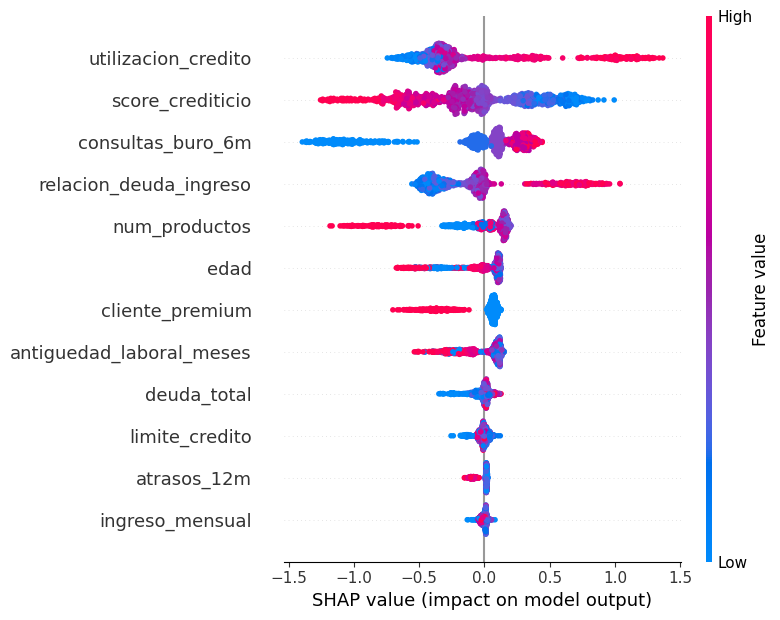

In [10]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb.named_steps["modelo"])

shap_values = explainer.shap_values(X_val)

shap.summary_plot(
    shap_values,
    X_val
)

## **Seleccionemos y analicemos un cliente en Particular:**

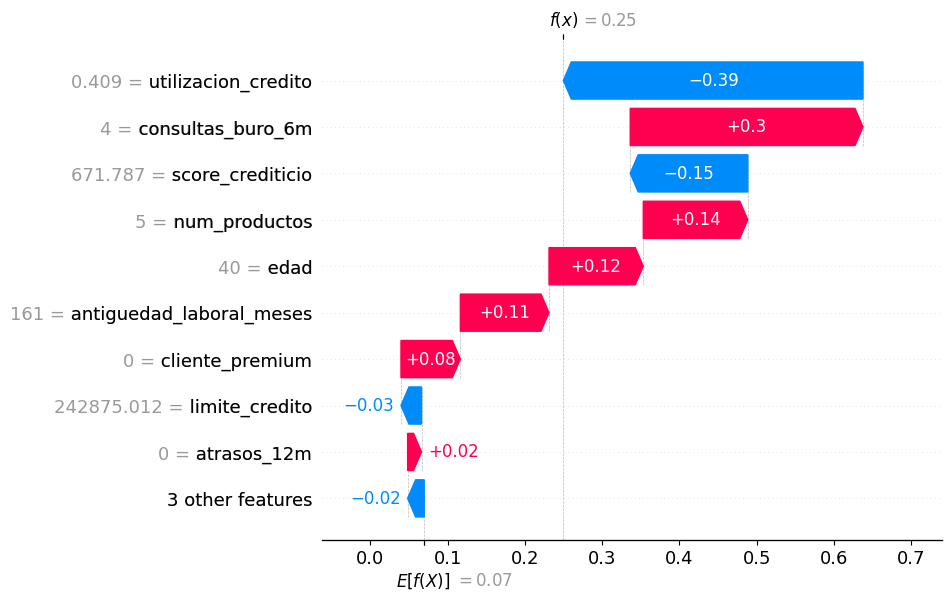

El cliente pertenece a la clase: [1]
Probabilidad de cada clase: [[0.43788695 0.56211305]]


In [11]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_val.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

print(f"El cliente pertenece a la clase: {xgb.predict(cliente)}")
print(f"Probabilidad de cada clase: {xgb.predict_proba(cliente)}")

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=0.25 (muy por encima del promedio E[f(X)]=0.07). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado, con una probabilidad de la clase 1 de 56.2%.

# **Análisis desde la perspectiva del negocio:**

In [12]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500

In [13]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo_val = xgb.predict_proba(X_val)[:, 1]
y_probs_mejor_modelo_test = xgb.predict_proba(X_test)[:, 1]


# 6to error: en el código original se utiliza y_test, pero esto es un
# error, porque el conjunto de prueba solo debe utilizarse para
# evaluar el desempeño final del modelo y no para decisiones de
# optimización.
utilidad_05 = utilidad(
    y_val,
    y_probs_mejor_modelo_val,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
44800


Mejor umbral: 0.67
Mayor Utilidad (USD): 49900


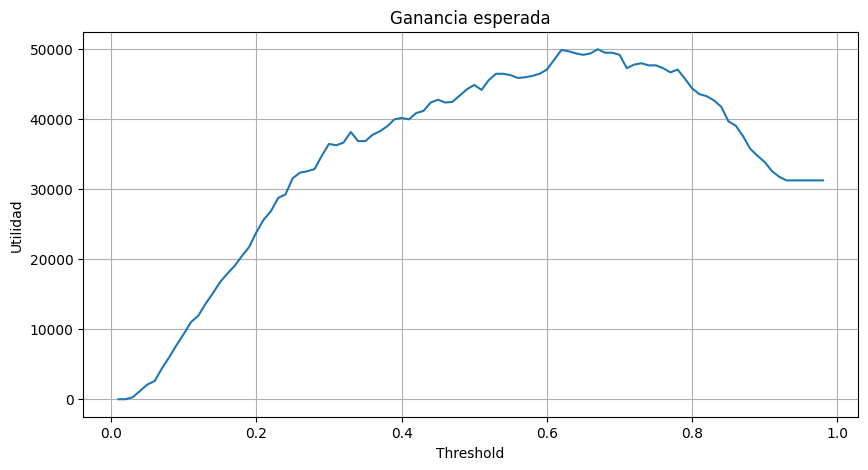

In [14]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_val,
        y_probs_mejor_modelo_val,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)

# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [15]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:

def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada

In [16]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo_test,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo_test,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo {best_threshold} : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $445,333
Threshold óptimo 0.67 : $432,000
Diferencia : $-13,333
Incremento : -3.0%


## **Matriz de Confusión**



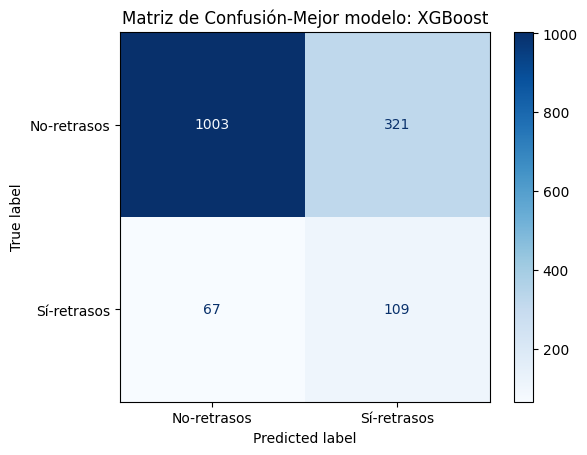

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["No-retrasos", "Sí-retrasos"]
y_pred_test = xgb.predict(X_test)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title("Matriz de Confusión-Mejor modelo: XGBoost")
plt.show()

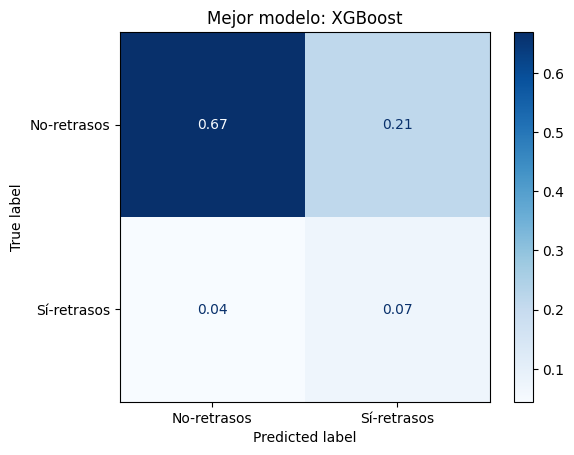

In [18]:
# O bien en su forma de proporciones:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos.
    values_format='.2f' # Total de decimales desplegadas.
)
plt.title("Mejor modelo: XGBoost")
plt.show()

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**

# Conclusiones particulares: Reporte de auditoría de modelos de riesgo crediticio

**Dirigido a:** CEO de CrediNova  
**Asunto:** Evaluación y recomendación de modelos de clasificación para riesgo crediticio

### 1. Objetivo del análisis

El objetivo de esta auditoría fue evaluar los modelos Árbol de Decisión, Random Forest y XGBoost para identificar cuál ofrece mejores resultados al predecir el incumplimiento de obligaciones financieras durante los siguientes 90 días.

Además del desempeño estadístico, se analizó el impacto económico de las decisiones de aprobación de crédito, considerando una ganancia de $100 USD por cada cliente aprobado que cumple sus obligaciones y una pérdida de $500 USD por cada cliente aprobado que incumple.

### 2. Principales hallazgos

Durante la revisión del código original se identificaron errores metodológicos que podían comprometer la confiabilidad de los resultados, entre ellos la presencia de variables con información futura, la aplicación incorrecta de técnicas de balanceo, la falta de una separación adecuada de los datos y la selección de métricas poco apropiadas para clases desbalanceadas.

Para corregir estos problemas, se implementó una metodología que separa los datos de entrenamiento, validación y prueba, optimiza los hiperparámetros mediante GridSearchCV y utiliza Average Precision como métrica principal de selección.

Adicionalmente, se incorporó la técnica combinada SMOTE + Tomek Links dentro de los pipelines de entrenamiento. SMOTE permite generar ejemplos sintéticos de la clase minoritaria, mientras que Tomek Links ayuda a eliminar observaciones de la clase mayoritaria cercanas a la frontera entre clases.

### 3. Comparación de modelos

XGBoost obtuvo el mejor desempeño en Average Precision, con un valor de 0.3698, seguido de Random Forest con 0.3410 y Árbol de Decisión con 0.3108. También presentó el mayor ROC-AUC, con 0.7714.

Sin embargo, Árbol de Decisión obtuvo una mayor exactitud y precisión en validación. Estos resultados muestran que los modelos presentan fortalezas distintas y que la selección debe considerar las características del problema y los objetivos del negocio.

Se seleccionó XGBoost como el principal candidato debido a su mejor capacidad para ordenar a los clientes según su riesgo de incumplimiento, utilizando Average Precision como criterio prioritario.

### 4. Impacto económico

Al evaluar diferentes umbrales de clasificación en el conjunto de validación, se identificó un umbral óptimo de 0.67. Con este valor, la utilidad aumentó de $44,800 USD, obtenidos con el umbral estándar de 0.50, a $49,900 USD, lo que representa una mejora aproximada del 11.4%.

Sin embargo, al evaluar ambos umbrales en el conjunto independiente de prueba y proyectar los resultados a 10,000 solicitudes, se obtuvieron los siguientes resultados:

- **Umbral 0.50:** $445,333 USD.
- **Umbral 0.67:** $432,000 USD.
- **Diferencia:** −$13,333 USD.
- **Variación porcentual:** −3.0%.

Aunque el umbral optimizado permitió incrementar la utilidad durante la validación, esta mejora no se mantuvo en el conjunto de prueba.

En comparación con el experimento anterior, la diferencia porcentual negativa se redujo de 7.9% a 3.0%. Esto representa un resultado más favorable en términos de estabilidad económica relativa, aunque todavía no demuestra que el umbral optimizado sea superior al estándar.

### 5. Recomendaciones

Se recomienda considerar XGBoost como el principal candidato para continuar con el proceso de validación, debido a su desempeño en Average Precision y ROC-AUC.

No obstante, no se recomienda desplegarlo inmediatamente en producción ni adoptar automáticamente el umbral de 0.67, ya que este último produjo una utilidad inferior a la obtenida con 0.50 en prueba.

También se recomienda evaluar la calibración de las probabilidades, realizar pruebas con información de periodos posteriores y analizar la estabilidad de las predicciones y de la utilidad económica.

### 6. Conclusión ejecutiva

La auditoría permitió comprobar que corregir los errores metodológicos y aplicar técnicas de balanceo apropiadas es fundamental para obtener resultados más confiables.

La combinación de SMOTE y Tomek Links permitió desarrollar una nueva alternativa de entrenamiento y reducir la diferencia porcentual negativa entre la utilidad del umbral estándar y la del umbral optimizado, en comparación con el experimento anterior.

XGBoost continúa siendo el principal candidato según las métricas de selección utilizadas. Sin embargo, los resultados económicos muestran que todavía es necesario realizar validaciones adicionales antes de recomendar su despliegue.

La principal recomendación para CrediNova es continuar evaluando el modelo, priorizando no solo su capacidad predictiva, sino también la estabilidad de sus decisiones y su rentabilidad con nuevos clientes.

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

# Conclusiones finales

A través de esta actividad comprendí la importancia de evaluar los modelos de aprendizaje automático más allá de sus resultados iniciales. Una exactitud elevada no necesariamente significa que un modelo sea confiable, especialmente cuando se trabaja con datos desbalanceados y con decisiones que tienen consecuencias económicas.

Uno de los principales aprendizajes fue identificar cómo la fuga de información, la separación incorrecta de los conjuntos de datos y la aplicación inadecuada de técnicas de balanceo pueden afectar la confiabilidad de las predicciones.

Durante el desarrollo de la actividad se probaron diferentes estrategias para tratar el desbalance de clases. Inicialmente se utilizó SMOTE y posteriormente se experimentó con pesos de clase. Finalmente, se implementó la combinación de SMOTE y Tomek Links, con el objetivo de generar ejemplos de la clase minoritaria y eliminar observaciones de la clase mayoritaria cercanas a la frontera de decisión.

Esta experiencia permitió comprender que no existe una técnica de balanceo que garantice mejores resultados en todos los casos y que es necesario evaluar su efecto tanto en las métricas de clasificación como en la utilidad económica.

La comparación entre Árbol de Decisión, Random Forest y XGBoost mostró que cada algoritmo presenta fortalezas diferentes. En esta versión, XGBoost obtuvo el mejor Average Precision, con 0.3698, y el mayor ROC-AUC, con 0.7714, mientras que Árbol de Decisión obtuvo mejores resultados en Accuracy y Precision.

Otro aprendizaje importante fue la influencia del umbral de clasificación sobre las decisiones del negocio. Con la combinación de SMOTE y Tomek Links se obtuvo un umbral óptimo de 0.67, que mejoró la utilidad en validación. Sin embargo, al evaluar el modelo sobre el conjunto de prueba, la utilidad proyectada a 10,000 solicitudes fue de $432,000 USD, frente a $445,333 USD con el umbral estándar de 0.50.

Aunque la diferencia continuó siendo negativa, se redujo de 7.9% en el experimento anterior a 3.0% en esta versión. Esto permitió observar que las modificaciones en el entrenamiento pueden cambiar las probabilidades estimadas, el umbral seleccionado y los resultados económicos, sin garantizar necesariamente una mejora en datos independientes.

También comprendí la importancia de utilizar herramientas de interpretabilidad, como la importancia de variables y SHAP, para analizar los factores que influyen en las predicciones y comprender mejor las decisiones individuales del modelo.

El uso de herramientas de inteligencia artificial generativa, como ChatGPT y Microsoft Copilot, fue de gran utilidad durante la auditoría. Estas herramientas facilitaron la identificación de errores metodológicos, la corrección de código, la configuración de GridSearchCV y la implementación de técnicas de balanceo como SMOTE y Tomek Links.

Su mayor aportación fue ayudarme a comprender conceptos técnicos y explorar alternativas de solución. Sin embargo, mi intervención fue fundamental para verificar las recomendaciones, interpretar los resultados y comprobar que las modificaciones realmente respondieran a los objetivos de la actividad.

En particular, fue necesario aplicar criterio propio para distinguir entre una mejora obtenida en validación y una mejora que también se mantiene en prueba, así como para interpretar correctamente las diferencias económicas entre los umbrales evaluados.

En conclusión, esta actividad permitió integrar conocimientos de aprendizaje automático, auditoría metodológica, tratamiento de datos desbalanceados, interpretabilidad y evaluación económica. El principal aprendizaje fue reconocer que la calidad de un modelo no depende únicamente de sus métricas, sino también de la confiabilidad de su proceso de construcción, su capacidad de generalización y su impacto real sobre las decisiones del negocio.


Microsoft. (2026). Copilot (basado en GPT-4) [Modelo de lenguaje grande], utilizado para corrección de ortografía y redacción, consulta de información.

OpenAI. (2026). ChatGPT (basado en GPT-4) [Modelo de lenguaje grande], utilizado para generación de código, corrección de errores y generación de reporte ejecutivo.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **<<< Fin de la Actividad de la Semana - Modelos de Árboles >>>**